# 11 — Memory-node sensitivity: does vLLM respond to the memory system?

**Objective.** Test the missing link between "vLLM is the best serving engine" and "vLLM is a suitable platform for HBM research":
does its throughput respond to the memory system in the regimes the thesis will study?

**Research question.** With the cores fixed on socket 0, what happens to vLLM BF16 (and to llama.cpp BF16 as a control) when the server's
memory sits on the other socket's node, where bandwidth is about one fifth and latency is higher?

**Data.** Campaign `online/membind-v2` (the corrected run; `membind` is the first attempt, kept as confounded, see the note below): four cells, each run as node 0, node 1, node 0, node 1 inside one Slurm job (two passes per node, three
repetitions per point): vLLM decode (128→512) at C = 1 and C = 128, vLLM 4096→1024 at C = 32, and llama.cpp decode at C = 1 (control).
`stream/calibration-membind1` gives the STREAM roof with remote memory. The superseded campaign `membind-v1-vllm-numa-override` is shown only to
document why it was discarded; `membind-shimcheck` is the placement check of the fix. Both vLLM and llama.cpp use `numactl --membind`;
vLLM needed an `LD_PRELOAD` shim because its CPU worker resets the memory policy to its first core's node
(`scripts/benchmark/numa_noop.c`, `docs/cluster_runbook.md`).

**Method.** The ratio remote ÷ local is formed inside each pass pair (same node, same day). Placement is checked per point from `numastat`.
The core PMU traffic proxy counts local reads only (notebook 01, section 4), so traffic with remote memory is **modelled**: bytes per step
measured with local memory (where the proxy is validated) × the remote step rate, compared with the remote STREAM roof at the same working set.

**Assumptions.** Bytes per step do not depend on where the memory sits (the same tokens per step are processed; checked below). Remote memory
changes bandwidth **and** latency; this experiment cannot separate them.

> **History and status.** The first run (campaign `membind`, jobs 5384321–5384324) loaded the NUMA shim with `apptainer --env LD_PRELOAD=<shim>`, which *replaced* the image's own
> `LD_PRELOAD` (tcmalloc and Intel OpenMP): its remote vLLM points ran without them (`libiomp is not found in LD_PRELOAD` in their `server.log`; the check is computed below). It was re-run as
> `membind-v2` with the shim prepended to the image preload; this notebook uses `membind-v2`, and the first run is compared with it below. Quantities that need the server's step counters
> are missing for four remote vLLM points whose telemetry was not yet synced (marked n/a); throughput, TPOT and TTFT come from the client and are complete.

In [1]:
import pandas as pd
from IPython.display import display

from llm_backend_analysis import paths
from llm_backend_analysis.analysis import membind
from llm_backend_analysis.data import loaders, registry
from llm_backend_analysis.reporting import Claim, claims_table, export_table, num, pct, rng, show, table, x
from llm_backend_analysis.visualization import plots, theme
from llm_backend_analysis.visualization.export import export_figure

theme.setup_notebook()
NOTEBOOK = "11_memory_node_sensitivity.ipynb"
pts = loaders.online_points(membind.CAMPAIGN, include_variants=True)
pts_v1 = loaders.online_points("membind", include_variants=True)   # first attempt: remote vLLM points without the image preload
stream = loaders.stream_calibration(None)
stream = stream[stream["threads"] == registry.topology()["compute_threads"]]
raw_online = paths.RAW / "online"

## 1. Was the memory where it was asked to be?

`numastat -p` of every server process is recorded after startup. A point is valid for this question only if at least 90% of the server's
resident memory is on the requested node.

In [2]:
place = membind.placement_table(raw_online, membind.CAMPAIGN)
first = membind.placement_table(raw_online, "membind-v1-vllm-numa-override")
check = membind.placement_table(raw_online, "membind-shimcheck")
rows = []
for name, d in ((f"{membind.CAMPAIGN} (used)", place), ("membind-shimcheck (fix check)", check), ("membind-v1-vllm-numa-override (superseded)", first)):
    for (arm, node), g in d.groupby(["arm", "mem_node"]):
        rows.append({"Campaign": name, "Arm": registry.configuration_label(registry.configuration_for_arm(arm).configuration_id),
                     "Memory node": node, "Points": len(g),
                     "Share on requested node": f"{pct(g['share_on_requested_node'].min(), 1, False)}–{pct(g['share_on_requested_node'].max(), 1, False)}",
                     "All valid": "yes" if g["valid"].all() else "no"})
display(table(pd.DataFrame(rows), align="left"))
remote_first = first[(first["arm"] == "vllm-bf16") & (first["mem_node"] == 1)]
show(f"With `numactl --membind=1` alone, vLLM kept only {rng(remote_first['share_on_requested_node'], lambda v: pct(v, 0, False))} of its memory on node 1 "
     f"(its CPU worker resets the policy to the node of its first core), so that attempt is not a remote-memory measurement and is not used. "
     f"With the shim, {int(place['valid'].sum())} of {len(place)} points of `{membind.CAMPAIGN}` have ≥ {membind.PLACEMENT_MIN:.0%} on the requested node "
     f"(llama.cpp needs no shim).")

Campaign,Arm,Memory node,Points,Share on requested node,All valid
membind-v2 (used),llama.cpp · BF16,0,2,100.0%–100.0%,yes
membind-v2 (used),llama.cpp · BF16,1,2,100.0%–100.0%,yes
membind-v2 (used),vLLM · BF16,0,6,100.0%–100.0%,yes
membind-v2 (used),vLLM · BF16,1,6,99.9%–100.0%,yes
membind-shimcheck (fix check),vLLM · BF16,1,1,100.0%–100.0%,yes
membind-v1-vllm-numa-override (superseded),vLLM · BF16,0,5,100.0%–100.0%,yes
membind-v1-vllm-numa-override (superseded),vLLM · BF16,1,5,5.1%–10.1%,no


With `numactl --membind=1` alone, vLLM kept only 5%–10% of its memory on node 1 (its CPU worker resets the policy to the node of its first core), so that attempt is not a remote-memory measurement and is not used. With the shim, 16 of 16 points of `membind-v2` have ≥ 90% on the requested node (llama.cpp needs no shim).

In [3]:
import re
rows = []
for f in sorted(p_ for c_ in ("membind", membind.CAMPAIGN) for p_ in (raw_online / c_).glob("*/vllm-bf16__*/*/*/server.log")):
    rows.append({"campaign": f.parts[-6], "arm_dir": f.parts[-4], "point": f"{f.parts[-3]}/{f.parts[-2]}",
                 "memory node": int(re.search(r"mem(\d)_", f.parts[-4]).group(1)),
                 "warning in server.log": "libiomp is not found in LD_PRELOAD" in f.read_text(errors="ignore")})
pre = pd.DataFrame(rows)
show("**Check of the confound.** vLLM points whose `server.log` carries the Intel-OpenMP warning, by campaign and memory node: "
     + "; ".join(f"`{c}` node {n}: {int(g['warning in server.log'].sum())} of {len(g)}" for (c, n), g in pre.groupby(["campaign", "memory node"])) + ".")

**Check of the confound.** vLLM points whose `server.log` carries the Intel-OpenMP warning, by campaign and memory node: `membind` node 0: 0 of 6; `membind` node 1: 6 of 6; `membind-v2` node 0: 0 of 6; `membind-v2` node 1: 0 of 6.

## 2. The remote-memory roof

STREAM triad on the server's 55 cores, same counters, with the memory on node 0 or node 1 (cache mode on both).

In [4]:
loc = stream[stream["campaign"] == "calibration"].set_index("working_set_gib")
rem = stream[stream["campaign"] == "calibration-membind1"].set_index("working_set_gib")
sizes = sorted(set(loc.index) & set(rem.index))
roof = pd.DataFrame({"Working set (GiB)": sizes, "Local, node 0 (GB/s)": [loc.loc[s, "stream_triad_gbs"] for s in sizes],
                     "Remote, node 1 (GB/s)": [rem.loc[s, "stream_triad_gbs"] for s in sizes]})
roof["Remote ÷ local"] = roof["Remote, node 1 (GB/s)"] / roof["Local, node 0 (GB/s)"]
roof["PMU capture, remote"] = [rem.loc[s, "pmu_total_over_stream"] for s in sizes]
display(table(roof, {"Local, node 0 (GB/s)": "{:.0f}", "Remote, node 1 (GB/s)": "{:.0f}", "Remote ÷ local": "{:.2f}×", "PMU capture, remote": "{:.2f}"}))
show(f"Remote memory sustains {rng(rem['stream_triad_gbs'], num)} GB/s and hardly changes with the working set, while the local rate falls from the HBM-cache regime to the DDR regime: "
     f"remote ÷ local is {x(roof['Remote ÷ local'].min(), 2)} at small working sets and {x(roof['Remote ÷ local'].max(), 2)} at {roof['Working set (GiB)'].max():g} GiB. "
     f"The core PMU captures only {rng(roof['PMU capture, remote'], num, nd=2)} of the modelled traffic (it counts local reads only), which is why traffic "
     "with remote memory is modelled below.")

Working set (GiB),"Local, node 0 (GB/s)","Remote, node 1 (GB/s)",Remote ÷ local,"PMU capture, remote"
4,519,104,0.20×,0.33
8,505,103,0.20×,0.33
16,484,102,0.21×,0.33
32,383,100,0.26×,0.33
48,302,99,0.33×,0.33
64,252,98,0.39×,0.33
96,191,96,0.50×,0.33


Remote memory sustains 96–104 GB/s and hardly changes with the working set, while the local rate falls from the HBM-cache regime to the DDR regime: remote ÷ local is 0.20× at small working sets and 0.50× at 96 GiB. The core PMU captures only 0.33 of the modelled traffic (it counts local reads only), which is why traffic with remote memory is modelled below.

## 3. What remote memory does to the server

In [5]:
tab = membind.sensitivity_table(pts, stream)
summ = membind.cell_summary(pts)
tab = tab.merge(summ[["model", "configuration_id", "workload", "concurrency", "throughput_ratio_min", "throughput_ratio_max",
                      "pass_cv_reference", "pass_cv_remote"]], on=["model", "configuration_id", "workload", "concurrency"])
view = pd.DataFrame({
    "Cell": [f"{registry.configuration_label(r.configuration_id)} {registry.workload_label(r.workload, short=True)}, C = {r.concurrency}" for r in tab.itertuples()],
    "Local tok/s": tab["reference_tok_s"], "Remote tok/s": tab["remote_tok_s"], "Remote ÷ local": tab["throughput_ratio"],
    "TPOT ×": tab["tpot_ratio_remote_over_reference"], "Step rate ×": tab["step_rate_ratio"],
    "Tokens/step local → remote": [f"{a:.1f} → {b:.1f}" if b == b else f"{a:.1f} → n/a" for a, b in zip(tab["tokens_per_step_reference"], tab["tokens_per_step_remote"])],
    "Bytes/step (GB)": tab["bytes_per_step_gb"], "Implied remote traffic (GB/s)": tab["implied_remote_traffic_gbs"],
    "Remote roof (GB/s)": tab["remote_roof_gbs"], "Remote roof share": tab["implied_remote_roof_share"],
    "Bound if bandwidth only": tab["bandwidth_only_ratio_bound"]})
display(table(view, {"Local tok/s": "{:.1f}", "Remote tok/s": "{:.1f}", "Remote ÷ local": "{:.3f}×", "TPOT ×": "{:.2f}×", "Step rate ×": "{:.3f}×",
                     "Bytes/step (GB)": "{:.1f}", "Implied remote traffic (GB/s)": "{:.0f}", "Remote roof (GB/s)": "{:.0f}",
                     "Remote roof share": "{:.0%}", "Bound if bandwidth only": "{:.2f}×"},
              caption="Remote (node 1) against local (node 0) memory, mean of two passes; TPOT × = remote ÷ local median TPOT"))
export_table(tab.drop(columns=["model"]), "membind_sensitivity")
v = tab[tab["configuration_id"] == "vllm_bf16"]
c = tab[tab["configuration_id"] == "llama_cpp_bf16"].iloc[0]
v1 = v[v["concurrency"] == 1].iloc[0]
hi = v[v["concurrency"] > 1]
show(f"With remote memory vLLM BF16 delivers {rng(v['throughput_ratio'], x, nd=2)} of its local throughput over the three regimes "
     f"(C = 1 decode {x(v1['throughput_ratio'], 2)}; llama.cpp control {x(c['throughput_ratio'], 2)}). The two passes of each node agree within "
     f"{pct(max(tab['pass_cv_reference'].max(), tab['pass_cv_remote'].max()), 1, False)} (CV), and the pass-pair ratios span "
     f"{rng(tab['throughput_ratio_max'] - tab['throughput_ratio_min'], lambda d: f'{d:.3f}')} in absolute terms.")
show(f"At C = 1 the server needs {pct(v1['implied_remote_roof_share'], 0, False)} (vLLM) and {pct(c['implied_remote_roof_share'], 0, False)} "
     f"(llama.cpp) of the remote roof. At C = 128 (the cells whose remote step counters are synced: {int(hi['implied_remote_roof_share'].notna().sum())} of {len(hi)}) the modelled traffic is only "
     f"{rng(hi['implied_remote_roof_share'].dropna(), lambda t: pct(t, 0, False))} of the remote roof, although the throughput falls to "
     f"{rng(hi['throughput_ratio'], x, nd=2)}, below the {rng(hi['bandwidth_only_ratio_bound'], x, nd=2)} that remote bandwidth alone would cap it at (the local runs needed "
     f"{rng(hi['reference_traffic_gbs'], num)} GB/s, more than the {rng(hi['remote_roof_gbs'], num)} GB/s the remote roof offers).")
tab_v1 = membind.sensitivity_table(pts_v1, stream)
cmp = tab[["configuration_id", "workload", "concurrency", "throughput_ratio"]].merge(
    tab_v1[["configuration_id", "workload", "concurrency", "throughput_ratio", "reference_tok_s"]],
    on=["configuration_id", "workload", "concurrency"], suffixes=("", "_first"))
cmp["Cell"] = [f"{registry.configuration_label(r.configuration_id)} {registry.workload_label(r.workload, short=True)}, C = {r.concurrency}" for r in cmp.itertuples()]
cmp["Change"] = cmp["throughput_ratio"] / cmp["throughput_ratio_first"] - 1
tab = tab.merge(cmp[["configuration_id", "workload", "concurrency", "Change", "throughput_ratio_first"]], on=["configuration_id", "workload", "concurrency"])
display(table(cmp[["Cell", "throughput_ratio_first", "throughput_ratio", "Change"]].rename(columns={"throughput_ratio_first": "First run (`membind`)", "throughput_ratio": "Corrected run (`membind-v2`)"}),
              {"First run (`membind`)": "{:.3f}×", "Corrected run (`membind-v2`)": "{:.3f}×", "Change": "{:+.1%}"},
              caption="Remote ÷ local throughput: first run (remote vLLM points without the image preload) against the corrected run"))
show(f"The missing preload changed the vLLM ratios by {rng(cmp[cmp['configuration_id'] == 'vllm_bf16']['Change'], lambda t: pct(t, 1))}; the llama.cpp control (no shim) by "
     f"{pct(cmp[cmp['configuration_id'] == 'llama_cpp_bf16']['Change'].iloc[0], 1)}, which is node-to-node variation of the control: its local rate was "
     f"{num(c['reference_tok_s'])} tok/s here and {num(cmp[cmp['configuration_id'] == 'llama_cpp_bf16']['reference_tok_s'].iloc[0])} tok/s on another node in the first run, while its remote rate barely moved.")


Cell,Local tok/s,Remote tok/s,Remote ÷ local,TPOT ×,Step rate ×,Tokens/step local → remote,Bytes/step (GB),Implied remote traffic (GB/s),Remote roof (GB/s),Remote roof share,Bound if bandwidth only
"vLLM · BF16 128→512, C = 1",21.9,6.6,0.299×,3.33×,0.299×,1.2 → 1.3,15.0,79,102,77%,0.39×
"vLLM · BF16 128→512, C = 128",833.8,170.6,0.205×,4.98×,0.205×,151.3 → 150.8,27.5,31,102,31%,0.67×
"llama.cpp · BF16 128→512, C = 1",24.9,8.0,0.321×,3.16×,0.320×,1.1 → 1.1,15.0,96,102,94%,0.34×
"vLLM · BF16 4096→1024, C = 32",609.5,150.9,0.248×,3.88×,–,122.1 → n/a,38.2,–,100,–,0.53×


With remote memory vLLM BF16 delivers 0.20×–0.30× of its local throughput over the three regimes (C = 1 decode 0.30×; llama.cpp control 0.32×). The two passes of each node agree within 1.2% (CV), and the pass-pair ratios span 0.000–0.004 in absolute terms.

At C = 1 the server needs 77% (vLLM) and 94% (llama.cpp) of the remote roof. At C = 128 (the cells whose remote step counters are synced: 1 of 2) the modelled traffic is only 31% of the remote roof, although the throughput falls to 0.20×–0.25×, below the 0.53×–0.67× that remote bandwidth alone would cap it at (the local runs needed 151–189 GB/s, more than the 100–102 GB/s the remote roof offers).

Cell,First run (`membind`),Corrected run (`membind-v2`),Change
"vLLM · BF16 128→512, C = 1",0.293×,0.299×,+2.0%
"vLLM · BF16 128→512, C = 128",0.194×,0.205×,+5.4%
"llama.cpp · BF16 128→512, C = 1",0.281×,0.321×,+14.3%
"vLLM · BF16 4096→1024, C = 32",0.245×,0.248×,+1.1%


The missing preload changed the vLLM ratios by +1.1%–+5.4%; the llama.cpp control (no shim) by +14.3%, which is node-to-node variation of the control: its local rate was 25 tok/s here and 28 tok/s on another node in the first run, while its remote rate barely moved.

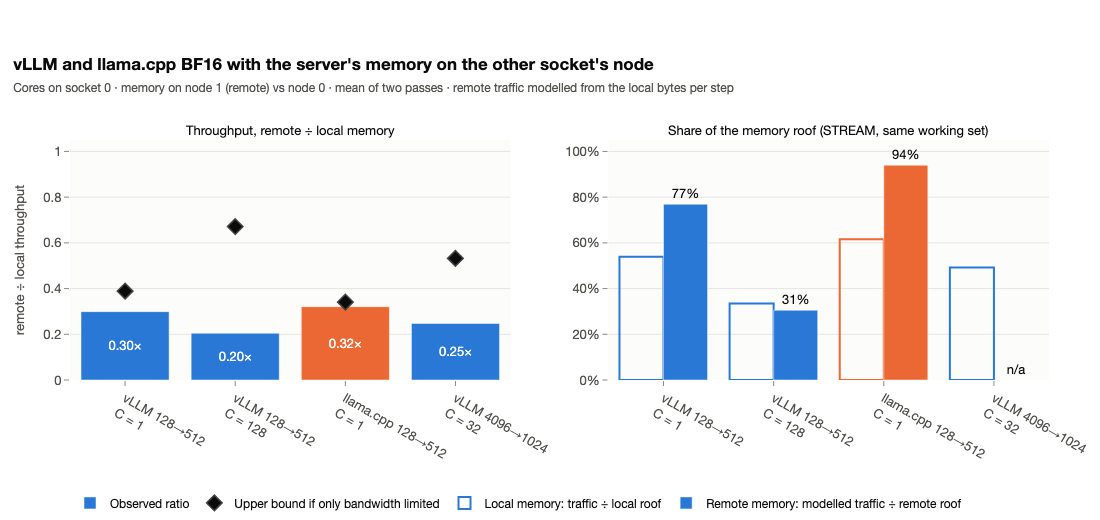

In [6]:
fig = plots.membind_figure(tab, title="vLLM and llama.cpp BF16 with the server's memory on the other socket's node",
                           subtitle="Cores on socket 0 · memory on node 1 (remote) vs node 0 · mean of two passes · remote traffic modelled from the local bytes per step")
fig.show()
export_figure(fig, "membind_ratio_and_traffic", source=NOTEBOOK,
              caption="Throughput with remote ÷ local memory per cell (bars) against the ratio that remote bandwidth alone would allow (diamonds), "
                      "and the share of the memory roof the server needs (remote traffic modelled from local bytes per step).")

**Interpretation.**
- *Measured.* vLLM's throughput falls to roughly a fifth to a third with remote memory in all three regimes, from single-request decode to
  128 concurrent requests and a long-context shape. Tokens per step are unchanged, so the work per step is the same: the steps become several times slower.
- *Measured, bandwidth-bound regime.* At C = 1 both engines need most of the remote roof (llama.cpp nearly all of it) and lose throughput in line
  with the bandwidth ratio: single-request decode is limited by the memory system in vLLM as in llama.cpp. vLLM uses a smaller share of the roof than llama.cpp,
  as it does of the local one (notebook 07).
- *Measured, high concurrency.* At C = 128 and at 4096→1024 the local runs needed more traffic (about 150 and 190 GB/s) than the remote roof offers (about 100 GB/s),
  so a loss was expected, but bandwidth alone would cap the ratio at roughly 0.5–0.7, and the observed ratio is about 0.2–0.25; where the remote step counters are synced (C = 128) the modelled remote traffic is only about 30% of the roof.
  vLLM at high concurrency is therefore sensitive to the memory system and not limited by compute: a memory system about five times worse moves its throughput by about five times.
- *Hypothesis, not tested here.* The additional loss comes from latency: remote accesses are slower (hw-bench reports 254 ns remote against 141 ns local idle
  latency in cache mode, repository `struggling-student/hw-bench`, `data/processed/thesis/locality.csv`; not measured in this campaign), and a step with
  many independent weight and KV streams may not have enough outstanding requests to hide it. Compute-core busy time stays near 95–100%, which does not discriminate (stalled cores count as busy).

**Implication for the thesis.** In the regimes it intends to study (low-batch decode, high-concurrency decode, long context), vLLM's throughput responds
strongly to the memory system. That supports vLLM as a platform on which HBM-versus-DDR differences can show up, and it replaces the earlier
"concurrency makes serving compute-bound" intuition by a measurement: at high concurrency vLLM remains memory-system sensitive even though its
traffic is far from the local roof.

## 4. Claims checked against the data

In [7]:
claims = [
    Claim("Every point of the campaign has at least 90% of the server's memory on the requested node", bool(place["valid"].all()),
          f"{len(place)} points, {rng(place['share_on_requested_node'], lambda t: pct(t, 1, False))}"),
    Claim("At the working sets of the cells (14–32 GiB) remote STREAM bandwidth is about one fifth to one quarter of the local rate", bool(tab["roof_ratio"].between(0.15, 0.3).all()),
          rng(tab["roof_ratio"], x, nd=2)),
    Claim("Throughput is lower with remote memory in every cell", bool((tab["throughput_ratio"] < 1).all()), rng(tab["throughput_ratio"], x, nd=2)),
    Claim("The llama.cpp control and vLLM lose the same fraction at C = 1 (within 5 percentage points)", bool(abs(c["throughput_ratio"] - v1["throughput_ratio"]) < 0.05),
          f"llama.cpp {x(c['throughput_ratio'], 2)}, vLLM {x(v1['throughput_ratio'], 2)}"),
    Claim("Each cell processes the same tokens per step with remote memory (within 5%)",
          bool(((tab["tokens_per_step_remote"] / tab["tokens_per_step_reference"] - 1).abs().dropna() < 0.05).all()),
          f"{rng((tab['tokens_per_step_remote'] / tab['tokens_per_step_reference']).dropna(), x, nd=2)} ({int(tab['tokens_per_step_remote'].notna().sum())} of {len(tab)} cells have remote step counters synced)"),
    Claim("No remote vLLM point of the corrected run carries the missing-preload warning, and the first run's remote points all do",
          bool(pre[(pre["campaign"] == membind.CAMPAIGN)]["warning in server.log"].sum() == 0 and pre[(pre["campaign"] == "membind") & (pre["memory node"] == 1)]["warning in server.log"].all()),
          "; ".join(f"`{c_}` node {n_}: {int(g_['warning in server.log'].sum())} of {len(g_)}" for (c_, n_), g_ in pre.groupby(["campaign", "memory node"]))),
    Claim("The corrected run changes the vLLM ratios of the first run by less than 10%", bool((cmp[cmp["configuration_id"] == "vllm_bf16"]["Change"].abs() < 0.10).all()),
          rng(cmp[cmp["configuration_id"] == "vllm_bf16"]["Change"], lambda t: pct(t, 1))),
    Claim("At C = 1 the server needs at least 70% of the remote roof (bandwidth-bound)", bool((tab[tab["concurrency"] == 1]["implied_remote_roof_share"] >= 0.7).all()),
          rng(tab[tab["concurrency"] == 1]["implied_remote_roof_share"], lambda t: pct(t, 0, False))),
    Claim("At high concurrency the observed ratio is less than half the bandwidth-only upper bound",
          bool((hi["throughput_ratio"] < 0.5 * hi["bandwidth_only_ratio_bound"]).all()),
          f"observed {rng(hi['throughput_ratio'], x, nd=2)} against a bound of {rng(hi['bandwidth_only_ratio_bound'], x, nd=2)}"),
    Claim("The two passes of a node agree within 2% (CV)", bool(max(tab["pass_cv_reference"].max(), tab["pass_cv_remote"].max()) < 0.02),
          pct(max(tab["pass_cv_reference"].max(), tab["pass_cv_remote"].max()), 1, False)),
]
display(claims_table(claims))

Holds,Statement,Evidence (computed)
✓,Every point of the campaign has at least 90% of the server's memory on the requested node,"16 points, 99.9%–100.0%"
✓,At the working sets of the cells (14–32 GiB) remote STREAM bandwidth is about one fifth to one quarter of the local rate,0.21×–0.26×
✓,Throughput is lower with remote memory in every cell,0.20×–0.32×
✓,The llama.cpp control and vLLM lose the same fraction at C = 1 (within 5 percentage points),"llama.cpp 0.32×, vLLM 0.30×"
✓,Each cell processes the same tokens per step with remote memory (within 5%),1.00×–1.03× (3 of 4 cells have remote step counters synced)
✓,"No remote vLLM point of the corrected run carries the missing-preload warning, and the first run's remote points all do",`membind` node 0: 0 of 6; `membind` node 1: 6 of 6; `membind-v2` node 0: 0 of 6; `membind-v2` node 1: 0 of 6
✓,The corrected run changes the vLLM ratios of the first run by less than 10%,+1.1%–+5.4%
✓,At C = 1 the server needs at least 70% of the remote roof (bandwidth-bound),77%–94%
✓,At high concurrency the observed ratio is less than half the bandwidth-only upper bound,observed 0.20×–0.25× against a bound of 0.53×–0.67×
✓,The two passes of a node agree within 2% (CV),1.2%


## Conclusions

- **Measured:** with the server's memory on the other socket's node (about one fifth of the local STREAM bandwidth) vLLM BF16 keeps a fifth to a third of its
  throughput in decode at C = 1, decode at C = 128 and 4096→1024 at C = 32; llama.cpp BF16 loses the same fraction at C = 1. At C = 1 this tracks the
  bandwidth ratio (both engines need most of the remote roof); at high concurrency the loss exceeds what remote bandwidth alone explains.
- **Interpretation:** vLLM's throughput responds to the memory system in every regime tested, including high concurrency where its local traffic is far below the
  roof. The excess loss at high concurrency is attributed to latency (hypothesis).
- **Implication for the thesis:** vLLM can expose memory-system differences across the regimes of interest, which closes the gap named in the review
  (objection O2) for this regime set. It does not show a difference between HBM and DDR.

## Limitations

- Remote memory is not "slower HBM": bandwidth and latency both change, and the cache-mode HBM of node 1 serves the remote accesses. Nothing here separates HBM from DDR
  or bandwidth from latency; that needs flat mode or uncore counters (tracker phase 4).
- Remote traffic is modelled from the local bytes per step; the core PMU reads zero remote reads. The assumption that bytes per step are unchanged is supported by equal tokens per step, not measured.
- Each cell ran on one node (two passes per memory node); three regimes at one concurrency each; the 4096→1024 shape is 78% prefill by operations (notebook 10).
- The STREAM roofs use the repository's Triad kernel (varied data, plain compiler loop, median): a sustained figure, not the hardware maximum.